# 05 - Fourier sous Heston : comparaison deep hedging vs Fourier

Pour chaque option (europeenne, asiatique, lookback) on superpose les
distributions de P&L des **trois reseaux** (VNN, SNN, RNN) et du **benchmark
analytique** (delta optimal Fourier-Heston, ou Black-Scholes naif pour le
lookback).

> Les P&L des reseaux sont **charges** depuis `results/heston_pnl.npz` :
> **executez d'abord le notebook 03** (qui entraine et sauvegarde). Ici on ne
> recalcule que le benchmark Fourier, sur le **meme** jeu test (seed=123), donc
> les courbes sont comparables sans reentrainer les reseaux.

In [11]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np

from fourier.heston import (
    compute_X0,
    compute_delta_vectorized,
    compute_call_asian,
    compute_delta_asian_vectorized,
)
from fourier.black_scholes import bs_lookback_call, bs_lookback_delta
from models import (
    compute_payoff_asian,
    compute_payoff_europeen,
    compute_payoff_lookback,
    simulate_heston,
)
from utils.plotting import plot_pnl_distribution

In [12]:
# Charger les P&L des reseaux (sauvegardes par le notebook 03)
PNL_FILE = PROJECT_ROOT / 'results' / 'heston_pnl.npz'
if not PNL_FILE.exists():
    raise FileNotFoundError(
        f"{PNL_FILE} introuvable. Executez d'abord le notebook 03 "
        "(deep hedging Heston) : il entraine les reseaux et sauvegarde les P&L.")
pnl = np.load(PNL_FILE)
print('P&L reseaux charges :', list(pnl.keys()))

# Re-simuler le MEME jeu test que le notebook 03 (memes parametres, seed=123)
S0, V0, K = 1.0, 0.0625, 1.0
kappa, theta, eta, rho = 4, 0.0625, 0.7, -0.7
T, J = 0.5, 126
I_test = 20_000
dt = T / J

S_test, V_test, dS_test, sigma_test, states_test = simulate_heston(
    S0, V0, kappa, theta, eta, rho, T, J, I_test, seed=123)
payoff_eu_test = compute_payoff_europeen(S_test, K)
payoff_as_test = compute_payoff_asian(S_test, K)
payoff_lb_test = compute_payoff_lookback(S_test)
print('S_test:', S_test.shape)

P&L reseaux charges : ['eu_vnn', 'eu_snn', 'eu_rnn', 'as_vnn', 'as_snn', 'as_rnn', 'lb_vnn', 'lb_snn', 'lb_rnn']
S_test: (20000, 127)


## Cas 1 : option europeenne

EU Fourier  MSE=2.528e-04  meanPnL=-7.744e-05


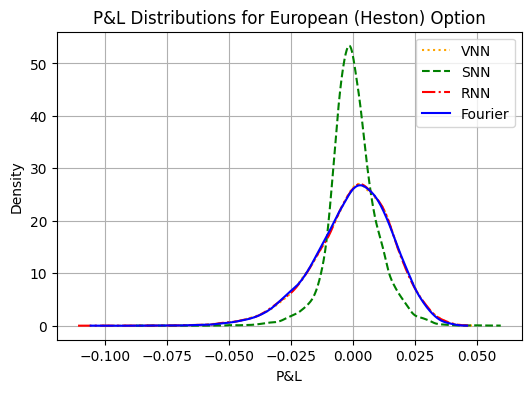

In [13]:
X0_eu = compute_X0(kappa=kappa, eta=eta, rho=rho, T=T, V0=V0, n_laguerre=128)
delta_eu = np.zeros((I_test, J))
for j in range(J):
    delta_eu[:, j] = compute_delta_vectorized(
        j * dt, S_test[:, j], V_test[:, j], kappa, theta, eta, rho, T, V0=V0, K=K, n_laguerre=128)
pnl_eu_fourier = X0_eu + np.sum(delta_eu * dS_test, axis=1) - payoff_eu_test
print(f'EU Fourier  MSE={np.mean(pnl_eu_fourier**2):.3e}  meanPnL={np.mean(pnl_eu_fourier):.3e}')

plot_pnl_distribution([
    (pnl['eu_vnn'],  'VNN',     'orange', 'dotted'),
    (pnl['eu_snn'],  'SNN',     'green',  'dashed'),
    (pnl['eu_rnn'],  'RNN',     'red',    'dashdot'),
    (pnl_eu_fourier, 'Fourier', 'blue',   'solid'),
], title='European (Heston)')

## Cas 2 : option asiatique (moyenne geometrique)

Asian Fourier  MSE=6.673e-05  meanPnL=-2.713e-04


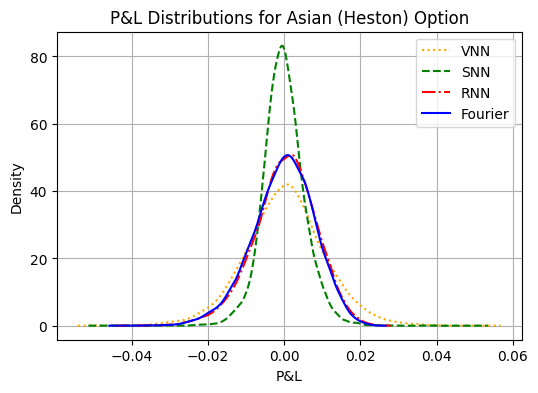

In [14]:
X0_as = compute_call_asian(S=1, moy_S=1, V_t=V0, t=0, K=K, T=T, V0=V0,
                           kappa=kappa, theta=theta, eta=eta, rho=rho, n_laguerre=128)
delta_as = np.zeros((I_test, J))
log_cumsum = np.zeros(I_test)
for j in range(J):
    bar_S_j = np.exp(log_cumsum / T)
    delta_as[:, j] = compute_delta_asian_vectorized(
        j * dt, S_test[:, j], V_test[:, j], bar_S_j, kappa, theta, eta, rho, T,
        V0=V0, K=K, n_laguerre=128)
    log_cumsum += np.log(S_test[:, j]) * dt
pnl_as_fourier = X0_as + np.sum(delta_as * dS_test, axis=1) - payoff_as_test
print(f'Asian Fourier  MSE={np.mean(pnl_as_fourier**2):.3e}  meanPnL={np.mean(pnl_as_fourier):.3e}')

plot_pnl_distribution([
    (pnl['as_vnn'],  'VNN',     'orange', 'dotted'),
    (pnl['as_snn'],  'SNN',     'green',  'dashed'),
    (pnl['as_rnn'],  'RNN',     'red',    'dashdot'),
    (pnl_as_fourier, 'Fourier', 'blue',   'solid'),
], title='Asian (Heston)')

## Cas 3 : option lookback

Benchmark **Black-Scholes naif** (pas de delta lookback-Heston en forme close).

LB BS naive  MSE=1.070e-03  meanPnL=3.829e-03


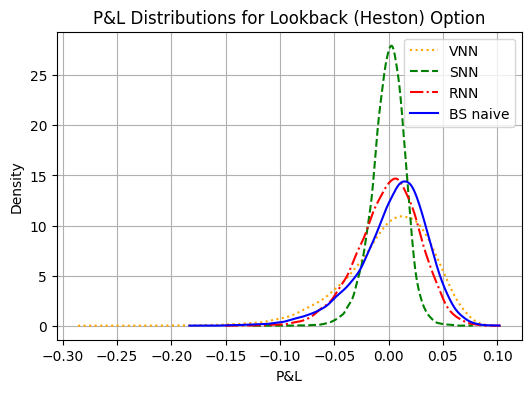

In [15]:
sigma_bs = 0.25
X0_lb = bs_lookback_call(S=1.0, m=1.0, tau=T, r=1e-5, sigma=sigma_bs)
delta_lb = np.zeros((I_test, J))
m_t = np.copy(S_test[:, 0])
for j in range(J):
    m_t = np.minimum(m_t, S_test[:, j])
    delta_lb[:, j] = bs_lookback_delta(S_test[:, j], m_t, T - j * dt, r=1e-5, sigma=sigma_bs)
pnl_lb_bs = X0_lb + np.sum(delta_lb * dS_test, axis=1) - payoff_lb_test
print(f'LB BS naive  MSE={np.mean(pnl_lb_bs**2):.3e}  meanPnL={np.mean(pnl_lb_bs):.3e}')

plot_pnl_distribution([
    (pnl['lb_vnn'], 'VNN',      'orange', 'dotted'),
    (pnl['lb_snn'], 'SNN',      'green',  'dashed'),
    (pnl['lb_rnn'], 'RNN',      'red',    'dashdot'),
    (pnl_lb_bs,     'BS naive', 'blue',   'solid'),
], title='Lookback (Heston)')